In [ ]:
!git clone https://github.com/Varshiireddy/asl-translator.git

Cloning into 'asl-translator'...
remote: Enumerating objects: 49, done.
remote: Counting objects: 100% (49/49), done.
remote: Compressing objects: 100% (40/40), done.
remote: Total 49 (delta 13), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (49/49), 281.36 KiB | 6.54 MiB/s, done.
Resolving deltas: 100% (13/13), done.


In [ ]:
import sys
sys.path.insert(0, "asl-translator/src")

from micrograd.engine import Value
from micrograd.nn import MLP

a = Value(2.0); b = Value(3.0)
f = (a / b) - a**2 + a.exp().log() + (1 - a) + (a * b).relu()
f.backward()
print(f, a.grad, b.grad)

Value(data=3.6667, grad=1.0000) -0.6666666666666665 1.7777777777777777


In [ ]:
!pip install -q kagglehub
import kagglehub

path = kagglehub.dataset_download("grassknoted/asl-alphabet")
print("Dataset folder:", path)

Using Colab cache for faster access to the 'asl-alphabet' dataset.
Dataset folder: /kaggle/input/asl-alphabet


In [ ]:
!pip install -q mediapipe
!wget -q https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task

import mediapipe as mp
from mediapipe.tasks import python as mp_tasks
from mediapipe.tasks.python import vision

options = vision.HandLandmarkerOptions(
    base_options=mp_tasks.BaseOptions(model_asset_path="hand_landmarker.task"),
    running_mode=vision.RunningMode.IMAGE,
    num_hands=1,
    min_hand_detection_confidence=0.3,
)
detector = vision.HandLandmarker.create_from_options(options)
print("Detector ready ✅")

Detector ready ✅


L photos found: 3000
First 3: ['L1.jpg', 'L2.jpg', 'L3.jpg']
Hands found: 1
Points shape: (21, 2)


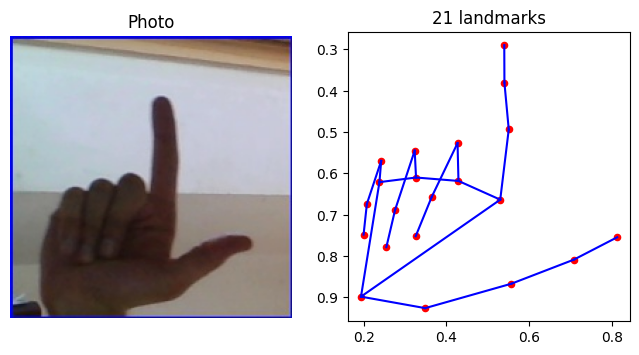

In [ ]:
import glob, os, re
import numpy as np
import matplotlib.pyplot as plt

LETTERS = ["A", "B", "C", "L", "Y"]

def letter_files(letter):
    files = glob.glob(f"{path}/**/asl_alphabet_train/{letter}/*.jpg", recursive=True)
    return sorted(files, key=lambda p: int(re.findall(r"\d+", os.path.basename(p))[0]))

print("L photos found:", len(letter_files("L")))
print("First 3:", [os.path.basename(f) for f in letter_files("L")[:3]])

HAND_CONNECTIONS = [(0,1),(1,2),(2,3),(3,4),(0,5),(5,6),(6,7),(7,8),(5,9),(9,10),(10,11),(11,12),
                    (9,13),(13,14),(14,15),(15,16),(13,17),(17,18),(18,19),(19,20),(0,17)]

img_path = letter_files("L")[100]
result = detector.detect(mp.Image.create_from_file(img_path))
print("Hands found:", len(result.hand_landmarks))

if result.hand_landmarks:
    pts = np.array([[lm.x, lm.y] for lm in result.hand_landmarks[0]])
    print("Points shape:", pts.shape)
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].imshow(plt.imread(img_path)); ax[0].set_title("Photo"); ax[0].axis("off")
    for a, b in HAND_CONNECTIONS:
        ax[1].plot(pts[[a, b], 0], pts[[a, b], 1], "b-")
    ax[1].scatter(pts[:, 0], pts[:, 1], c="red", s=20)
    ax[1].invert_yaxis(); ax[1].set_aspect("equal"); ax[1].set_title("21 landmarks")
    plt.savefig("landmarks_example.png"); plt.show()

In [ ]:
def to_features(landmarks):
    pts = np.array([[lm.x, lm.y] for lm in landmarks])
    pts = pts - pts[0]
    pts = pts / np.abs(pts).max()
    return pts.flatten()

def extract(files):
    feats = []
    for f in files:
        res = detector.detect(mp.Image.create_from_file(f))
        if res.hand_landmarks:
            feats.append(to_features(res.hand_landmarks[0]))
    return feats

X_train, y_train, X_test, y_test = [], [], [], []
for label, letter in enumerate(LETTERS):
    files = letter_files(letter)
    tr = extract(files[0:2000:10])
    te = extract(files[2400:3000:10])
    X_train += tr; y_train += [label] * len(tr)
    X_test  += te; y_test  += [label] * len(te)
    print(f"{letter}: train {len(tr)}/200, test {len(te)}/60")

X_train, X_test = np.array(X_train), np.array(X_test)
y_train, y_test = np.array(y_train), np.array(y_test)
print("X_train:", X_train.shape, " X_test:", X_test.shape)
np.savez("landmarks_5letters.npz", X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test)

A: train 170/200, test 23/60
B: train 169/200, test 17/60
C: train 168/200, test 16/60
L: train 190/200, test 36/60
Y: train 199/200, test 25/60
X_train: (896, 42)  X_test: (117, 42)


In [ ]:
X_test, y_test = [], []
for label, letter in enumerate(LETTERS):
    te = extract(letter_files(letter)[2400:3000:5])
    X_test += te; y_test += [label] * len(te)
    print(f"{letter}: test {len(te)}/120")

X_test, y_test = np.array(X_test), np.array(y_test)
print("X_test:", X_test.shape)
np.savez("landmarks_5letters.npz", X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test)

A: test 43/120
B: test 32/120
C: test 32/120
L: test 72/120
Y: test 51/120
X_test: (230, 42)


In [ ]:
import random, math

def softmax_cross_entropy(logits, y):
    m = max(o.data for o in logits)
    exps = [(o - m).exp() for o in logits]
    total = sum(exps)
    prob_correct = exps[y] / total
    return -prob_correct.log()

random.seed(42)
model = MLP(42, [16, 5])
print("Parameters:", len(model.parameters()))

x0, y0 = X_train[0].tolist(), int(y_train[0])
scores = model(x0)
print("Scores for first photo:", [round(s.data, 3) for s in scores])
print("Correct letter:", LETTERS[y0])
print("Loss:", round(softmax_cross_entropy(scores, y0).data, 3), " (random guess ≈", round(math.log(5), 3), ")")

Parameters: 773
Scores for first photo: [0.024, -0.163, -0.321, 0.003, 0.396]
Correct letter: A
Loss: 1.603  (random guess ≈ 1.609 )


epoch  1  loss 1.410  (49s)
epoch  2  loss 0.953  (100s)
epoch  3  loss 0.581  (151s)
epoch  4  loss 0.346  (202s)
epoch  5  loss 0.229  (253s)
epoch  6  loss 0.165  (304s)
epoch  7  loss 0.127  (355s)
epoch  8  loss 0.105  (408s)
epoch  9  loss 0.090  (460s)
epoch 10  loss 0.079  (512s)
epoch 11  loss 0.071  (564s)
epoch 12  loss 0.065  (615s)
epoch 13  loss 0.060  (667s)
epoch 14  loss 0.056  (719s)
epoch 15  loss 0.053  (771s)


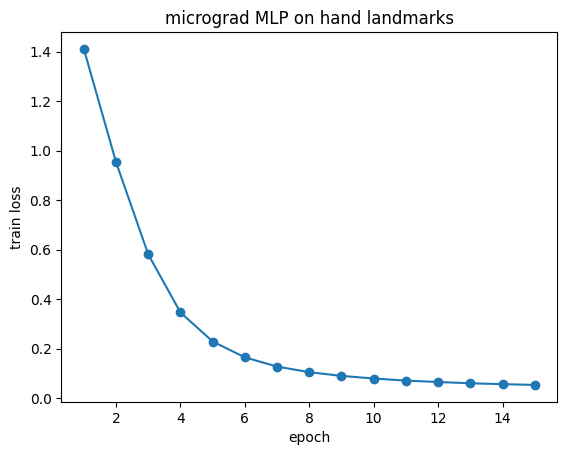

In [ ]:
import time

Xtr, ytr = X_train.tolist(), y_train.tolist()
lr, batch_size, epochs = 0.1, 32, 15
losses = []

start = time.time()
for epoch in range(epochs):
    idx = list(range(len(Xtr)))
    random.shuffle(idx)
    total = 0.0
    for s in range(0, len(idx), batch_size):
        batch = idx[s:s + batch_size]
        loss = sum(softmax_cross_entropy(model(Xtr[i]), ytr[i]) for i in batch) / len(batch)
        model.zero_grad()
        loss.backward()
        for p in model.parameters():
            p.data -= lr * p.grad
        total += loss.data * len(batch)
    losses.append(total / len(idx))
    print(f"epoch {epoch+1:2d}  loss {losses[-1]:.3f}  ({time.time() - start:.0f}s)")

plt.plot(range(1, epochs + 1), losses, marker="o")
plt.xlabel("epoch"); plt.ylabel("train loss"); plt.title("micrograd MLP on hand landmarks")
plt.savefig("day3_loss.png"); plt.show()

In [21]:
def predict(x):
    scores = model(x)
    return max(range(len(scores)), key=lambda k: scores[k].data)

train_preds = np.array([predict(x) for x in X_train.tolist()])
test_preds  = np.array([predict(x) for x in X_test.tolist()])

print(f"Train accuracy: {(train_preds == y_train).mean():.1%}")
print(f"Test accuracy:  {(test_preds == y_test).mean():.1%}")
print("Random guess:   20.0%\n")

print("Per letter (test):")
for k, letter in enumerate(LETTERS):
    mask = y_test == k
    print(f"  {letter}: {(test_preds[mask] == k).mean():.0%}  ({mask.sum()} photos)")

Train accuracy: 99.3%
Test accuracy:  96.5%
Random guess:   20.0%

Per letter (test):
  A: 88%  (43 photos)
  B: 100%  (32 photos)
  C: 100%  (32 photos)
  L: 100%  (72 photos)
  Y: 94%  (51 photos)
